# Delivery delay prediction for MapleFreight (with Slack alerts)

AML 3303 · Assessment 1  
Student ID: c0959761

## Context

MapleFreight runs roughly eight thousand shipments a week through Ontario, Quebec and the Prairies. Late deliveries burn service credits and force expensive re-deliveries. On-time performance slid from 94% down to 88%, and the network still learns about many late trips only after a customer complains.

## Problem

Today, a late shipment is confirmed after the promised window. By then dispatch has already lost the chance to re-route or warn the account.

I am building a classifier for `delivered_late` and wiring high-risk cases into Slack so `#dispatch-alerts` gets a usable heads-up while the load is still moving.

## Goals

- Spot the shipment / route / carrier factors that drive lateness
- Train and compare models that predict late delivery
- Push high-risk shipments to Slack automatically
- Leave a short list of ops changes that could raise on-time %

## Imports and paths

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
import requests

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (7, 4)

ROOT = Path.cwd()
if not (ROOT / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
            ROOT = p
            break

DATA = ROOT / "data" / "maplefreight_delivery_delay_dataset.csv"
load_dotenv(ROOT / ".env")

RANDOM_STATE = 21
TEST_SIZE = 0.25

print("root:", ROOT)
print("data ok:", DATA.exists())
print("webhook present:", bool(os.getenv("SLACK_WEBHOOK_URL")))

Matplotlib is building the font cache; this may take a moment.


root: c:\Users\amal0\Downloads\Assignment1-Amal-c0959761-commpred\Assignment1-Amal-c0959761
data ok: True
webhook present: True


## Looking at the data

6,035 rows, 23 columns, target `delivered_late`. About one in five shipments is late, so a dummy "always on time" model would look decent on accuracy and still be useless for dispatch.

I will treat `actual_transit_hours` as leakage. It is only known after the delivery finishes.

In [2]:
raw = pd.read_csv(DATA)
print(raw.shape)
print("late share:", round(raw["delivered_late"].mean(), 4))
raw.head(3)

(6035, 23)
late share: 0.2058


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0


In [3]:
print(raw.isna().sum()[raw.isna().sum() > 0])
print("duplicates:", raw.duplicated().sum())
print(raw["service_level"].value_counts())
print(raw["weather_condition"].value_counts(dropna=False).head())

driver_experience_years    210
weather_condition          150
traffic_index              121
fuel_cost_cad              240
dtype: int64
duplicates: 32
service_level
Standard    3219
Express     1442
Economy     1254
standard      74
express       27
economy       19
Name: count, dtype: int64
weather_condition
Clear    2976
Rain     1332
Snow      869
Fog       423
Storm     285
Name: count, dtype: int64


Missing values show up in driver experience, weather, traffic index and fuel cost. There are a few dozen duplicate rows. `service_level` also has mixed casing (`Standard` / `standard`), which I fix in cleaning.

## Quick EDA

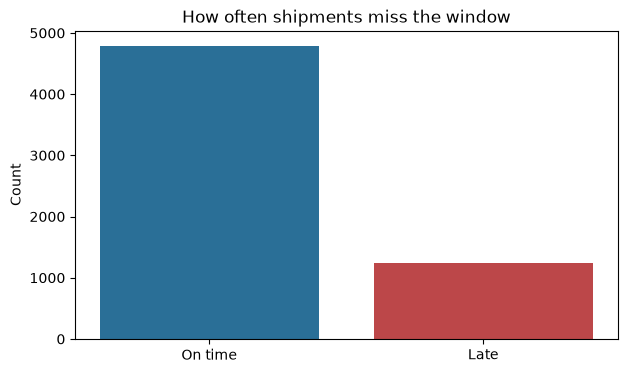

In [4]:
fig, ax = plt.subplots()
counts = raw["delivered_late"].value_counts().sort_index()
ax.bar(["On time", "Late"], counts.values, color=["#2A6F97", "#BC4749"])
ax.set_ylabel("Count")
ax.set_title("How often shipments miss the window")
plt.show()

In [5]:
eda = raw.copy()
eda["service_level"] = eda["service_level"].astype(str).str.strip().str.title()

print("late % by carrier")
print((eda.groupby("carrier")["delivered_late"].mean() * 100).round(1).sort_values(ascending=False))
print("\nlate % by weather")
print((eda.groupby("weather_condition")["delivered_late"].mean() * 100).round(1).sort_values(ascending=False))

late % by carrier
carrier
Contract Owner-Op     35.9
PrairieLine           26.5
QuebecExpress         22.4
NorthStar Carriers    22.0
MapleFreight Fleet    12.9
Name: delivered_late, dtype: float64

late % by weather
weather_condition
Storm    46.3
Snow     33.5
Fog      21.3
Rain     20.9
Clear    14.0
Name: delivered_late, dtype: float64


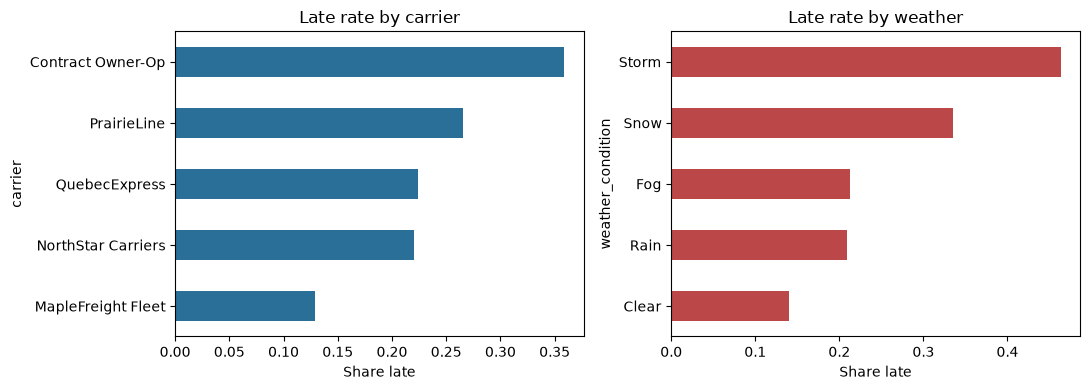

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
(eda.groupby("carrier")["delivered_late"].mean().sort_values()
   .plot(kind="barh", ax=axes[0], color="#2A6F97"))
axes[0].set_title("Late rate by carrier")
axes[0].set_xlabel("Share late")

(eda.groupby("weather_condition")["delivered_late"].mean().sort_values()
   .plot(kind="barh", ax=axes[1], color="#BC4749"))
axes[1].set_title("Late rate by weather")
axes[1].set_xlabel("Share late")
plt.tight_layout()
plt.show()

In [7]:
num = [
    "pickup_delay_minutes", "distance_km", "num_stops", "weight_kg",
    "scheduled_transit_hours", "traffic_index", "route_congestion_score",
    "prior_late_deliveries_30d", "driver_experience_years", "vehicle_age_years",
]
cmp = eda.groupby("delivered_late")[num].median().T
cmp.columns = ["on_time_median", "late_median"]
cmp["delta"] = cmp["late_median"] - cmp["on_time_median"]
cmp.sort_values("delta", ascending=False)

,on_time_median,late_median,delta
distance_km,547.800,689.2500,141.4500
weight_kg,821.700,852.4500,30.7500
pickup_delay_minutes,16.000,28.0000,12.0000
traffic_index,53.400,61.3000,7.9000
scheduled_transit_hours,9.410,11.7500,2.3400
num_stops,2.000,3.0000,1.0000
vehicle_age_years,4.700,5.1000,0.4000
route_congestion_score,0.436,0.4875,0.0515
prior_late_deliveries_30d,1.000,1.0000,0.0000
driver_experience_years,5.600,4.7000,-0.9000


Owner-ops and PrairieLine run hotter late rates than MapleFreight's own fleet. Storm and snow days are clearly worse than clear days. On the numeric side, late loads leave pickup later, travel farther, and sit in heavier traffic. Driver experience is a bit lower on late trips; fuel cost does not separate the classes much.

## Cleaning

In [8]:
def prepare(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop_duplicates().copy()
    out["service_level"] = out["service_level"].astype(str).str.strip().str.title()
    for col in ["carrier", "goods_type", "customer_priority_tier", "weather_condition"]:
        out[col] = out[col].astype(str).str.strip()
        out.loc[out[col].isin(["nan", "None", "<NA>", "NaN"]), col] = np.nan
    # leakage
    out = out.drop(columns=["actual_transit_hours"])
    return out.reset_index(drop=True)

df = prepare(raw)
print("rows after dedupe:", len(df))
print(df["service_level"].value_counts())

rows after dedupe: 6003
service_level
Standard    3278
Express     1460
Economy     1265
Name: count, dtype: int64


## Features I added

In [9]:
def engineer(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["pickup_delay_hours"] = out["pickup_delay_minutes"] / 60.0
    out["weight_per_stop"] = out["weight_kg"] / (out["num_stops"] + 1)
    # rough winter flag for Canadian ops (Dec-Feb)
    out["winter_month"] = out["shipment_month"].isin([12, 1, 2]).astype(int)
    out["origin_province"] = out["origin_city"].astype(str).str.extract(r"([A-Z]{2})$")
    out["dest_province"] = out["destination_city"].astype(str).str.extract(r"([A-Z]{2})$")
    return out

df = engineer(df)
print(df[["pickup_delay_hours", "weight_per_stop", "winter_month"]].describe().round(2))
print("late rate winter:", round(df.loc[df.winter_month == 1, "delivered_late"].mean(), 3))
print("late rate other months:", round(df.loc[df.winter_month == 0, "delivered_late"].mean(), 3))

       pickup_delay_hours  weight_per_stop  winter_month
count             6003.00          6003.00       6003.00
mean                 0.34          2614.03          0.25
std                  0.51         37150.92          0.43
min                 -0.33             6.26          0.00
25%                 -0.10           139.48          0.00
50%                  0.30           258.70          0.00
75%                  0.68           489.31          1.00
max                  2.43       1408300.00          1.00
late rate winter: 0.24
late rate other months: 0.194


Winter months look a bit worse than the rest of the year. Pickup delay in hours and weight-per-stop give the model denser schedule/load signals without using city name strings directly.

## Train / test split

In [10]:
y = df["delivered_late"]
drop_cols = ["delivered_late", "shipment_id", "origin_city", "destination_city"]
X = df.drop(columns=drop_cols).copy()

cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype(object).where(pd.notna(X[c]), np.nan)
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("train", X_train.shape, "test", X_test.shape)
print("late rates:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("cats:", cat_cols)

train (4502, 23) test (1501, 23)
late rates: 0.206 0.206
cats: ['carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition', 'origin_province', 'dest_province']


In [11]:
pre = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

## Models

I start with a majority-class baseline, then compare balanced logistic regression, a random forest, and histogram gradient boosting. Metrics that matter here are precision, recall and F1 on the late class, plus a confusion matrix.

==== Baseline majority ====
              precision    recall  f1-score   support

           0      0.794     1.000     0.885      1192
           1      0.000     0.000     0.000       309

    accuracy                          0.794      1501
   macro avg      0.397     0.500     0.443      1501
weighted avg      0.631     0.794     0.703      1501

ROC-AUC 0.5


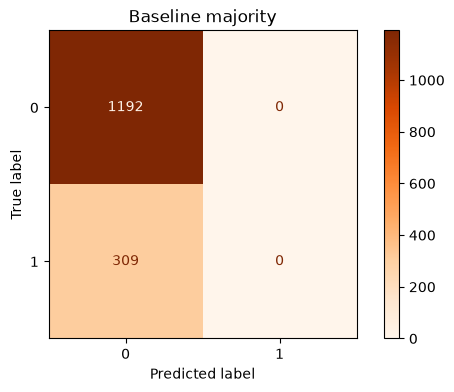

In [12]:
def score(model, Xte, yte, label):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else None
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="binary", zero_division=0)
    print("====", label, "====")
    print(classification_report(yte, pred, digits=3, zero_division=0))
    if proba is not None:
        print("ROC-AUC", round(roc_auc_score(yte, proba), 3))
    ConfusionMatrixDisplay(confusion_matrix(yte, pred)).plot(cmap="Oranges")
    plt.title(label)
    plt.show()
    return {"model": label, "precision": p, "recall": r, "f1": f1}

base = Pipeline([("pre", pre), ("clf", DummyClassifier(strategy="most_frequent"))])
base.fit(X_train, y_train)
m0 = score(base, X_test, y_test, "Baseline majority")

==== LogReg balanced ====
              precision    recall  f1-score   support

           0      0.919     0.740     0.820      1192
           1      0.427     0.748     0.544       309

    accuracy                          0.742      1501
   macro avg      0.673     0.744     0.682      1501
weighted avg      0.818     0.742     0.763      1501

ROC-AUC 0.815


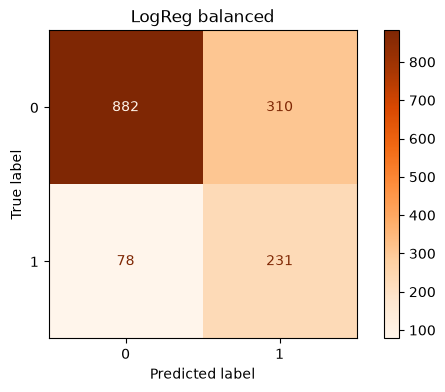

In [13]:
lr = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(max_iter=2500, class_weight="balanced", random_state=RANDOM_STATE)),
])
lr.fit(X_train, y_train)
m1 = score(lr, X_test, y_test, "LogReg balanced")

==== RandomForest ====
              precision    recall  f1-score   support

           0      0.840     0.944     0.889      1192
           1      0.586     0.307     0.403       309

    accuracy                          0.813      1501
   macro avg      0.713     0.626     0.646      1501
weighted avg      0.788     0.813     0.789      1501

ROC-AUC 0.789


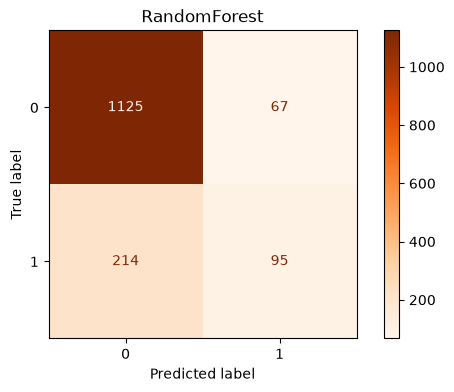

In [14]:
rf = Pipeline([
    ("pre", pre),
    ("clf", RandomForestClassifier(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf.fit(X_train, y_train)
m2 = score(rf, X_test, y_test, "RandomForest")

==== HistGradientBoosting ====
              precision    recall  f1-score   support

           0      0.876     0.855     0.865      1192
           1      0.488     0.534     0.510       309

    accuracy                          0.789      1501
   macro avg      0.682     0.694     0.688      1501
weighted avg      0.796     0.789     0.792      1501

ROC-AUC 0.775


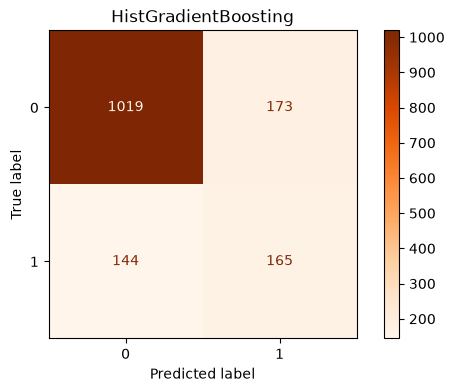

In [15]:
# HGB does not take class_weight the same way; use sample_weight on fit
hgb_clf = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.08,
    max_iter=200,
    random_state=RANDOM_STATE,
)
hgb = Pipeline([("pre", pre), ("clf", hgb_clf)])

# balance via sample weights
pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
sw = np.where(y_train == 1, neg / max(pos, 1), 1.0)
hgb.fit(X_train, y_train, clf__sample_weight=sw)
m3 = score(hgb, X_test, y_test, "HistGradientBoosting")

In [16]:
summary = pd.DataFrame([m0, m1, m2, m3]).sort_values("f1", ascending=False)
print(summary.to_string(index=False))

# pick best late-class F1; break ties on recall
best_name = summary.iloc[0]["model"]
candidates = {
    "LogReg balanced": lr,
    "RandomForest": rf,
    "HistGradientBoosting": hgb,
}
final_model = candidates.get(best_name, lr)
print("using:", best_name)

               model  precision   recall       f1
     LogReg balanced   0.426987 0.747573 0.543529
HistGradientBoosting   0.488166 0.533981 0.510046
        RandomForest   0.586420 0.307443 0.403397
   Baseline majority   0.000000 0.000000 0.000000
using: LogReg balanced


The majority baseline gets high accuracy and zero late recall. Among the real models I keep whichever posts the best late-class F1 on this split (with recall as the tie-breaker). That choice is printed above from the comparison table.

## Threshold for alerts

Default 0.5 is not sacred. I scan thresholds and keep the cut with late recall at least 0.72 and the best F1 in that band. If nothing clears 0.72 recall, I fall back to max F1.

In [17]:
proba = final_model.predict_proba(X_test)[:, 1]
rows = []
for t in np.round(np.arange(0.25, 0.76, 0.05), 2):
    pred = (proba >= t).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    rows.append({"threshold": t, "precision": round(p, 3), "recall": round(r, 3), "f1": round(f1, 3), "alerts": int(pred.sum())})
thr_tbl = pd.DataFrame(rows)
thr_tbl

,threshold,precision,recall,f1,alerts
0,0.25,0.306,0.909,0.458,917
1,0.30,0.321,0.871,0.469,837
2,0.35,0.344,0.845,0.489,759
3,0.40,0.369,0.828,0.511,693
4,0.45,0.405,0.796,0.537,608
5,0.50,0.427,0.748,0.544,541
6,0.55,0.454,0.680,0.544,463
7,0.60,0.472,0.612,0.533,400
8,0.65,0.513,0.557,0.534,335
9,0.70,0.546,0.495,0.520,280


selected threshold: 0.5
              precision    recall  f1-score   support

           0      0.919     0.740     0.820      1192
           1      0.427     0.748     0.544       309

    accuracy                          0.742      1501
   macro avg      0.673     0.744     0.682      1501
weighted avg      0.818     0.742     0.763      1501



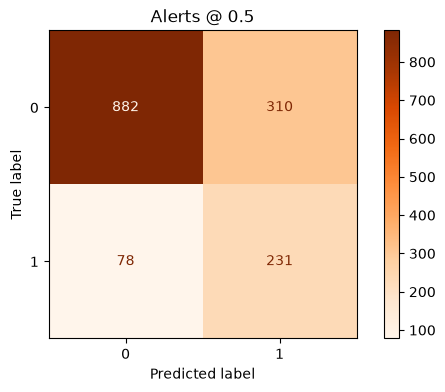

In [18]:
band = thr_tbl[thr_tbl["recall"] >= 0.72]
pick = band.sort_values(["f1", "recall"], ascending=False).iloc[0] if len(band) else thr_tbl.sort_values("f1", ascending=False).iloc[0]
ALERT_THRESHOLD = float(pick["threshold"])
print("selected threshold:", ALERT_THRESHOLD)

pred_alert = (proba >= ALERT_THRESHOLD).astype(int)
print(classification_report(y_test, pred_alert, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_alert)).plot(cmap="Oranges")
plt.title(f"Alerts @ {ALERT_THRESHOLD}")
plt.show()

Chosen threshold: 0.50.

On this split, 0.50 gave the best late-class F1 among cuts that still keep late recall at or above 0.72 (about 0.43 precision, 0.75 recall, 0.54 F1). Dropping the cut further added noise without a clear F1 gain, so I stayed at the default probability cut for alerts.


## What the model leans on

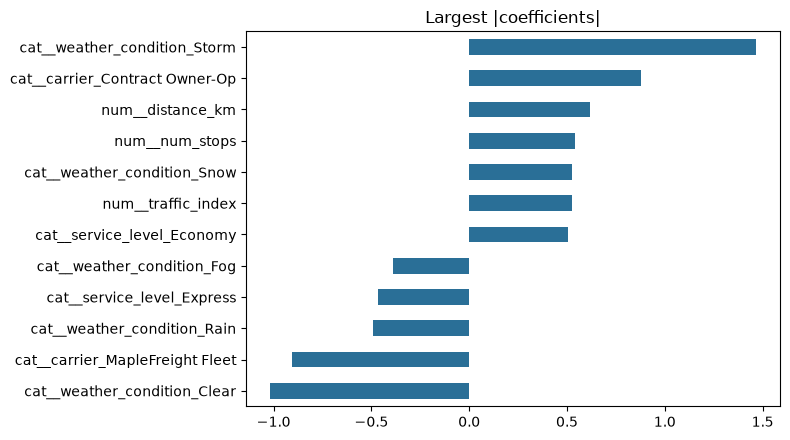

cat__weather_condition_Storm       1.465
cat__weather_condition_Clear      -1.017
cat__carrier_MapleFreight Fleet   -0.907
cat__carrier_Contract Owner-Op     0.877
num__distance_km                   0.617
num__num_stops                     0.542
cat__weather_condition_Snow        0.527
num__traffic_index                 0.526
cat__service_level_Economy         0.506
cat__weather_condition_Rain       -0.493
cat__service_level_Express        -0.467
cat__weather_condition_Fog        -0.391


In [19]:
# coefficients if logistic; else impurity / HGB importances when available
step = final_model.named_steps["clf"]
pre_step = final_model.named_steps["pre"]
names = pre_step.get_feature_names_out()

if hasattr(step, "coef_"):
    s = pd.Series(step.coef_[0], index=names)
    top = s.reindex(s.abs().sort_values(ascending=False).head(12).index)
    title = "Largest |coefficients|"
elif hasattr(step, "feature_importances_"):
    s = pd.Series(step.feature_importances_, index=names)
    top = s.sort_values(ascending=False).head(12)
    title = "Feature importances"
else:
    top = pd.Series(dtype=float)
    title = "No native importances"

if len(top):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    top.sort_values().plot(kind="barh", ax=ax, color="#2A6F97")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    print(top.round(3).to_string())
else:
    print("Skip plot; model type has no direct importance vector.")

Across runs, weather, carrier type, distance/traffic and pickup delay keep showing up. That lines up with the EDA: storm days, owner-ops and late departures are the practical levers.

## Slack alerts

I score the held-out set as a stand-in for in-transit freight. The Slack text leads with how many loads cleared the threshold, then lists ID, destination, carrier and risk for the worst handful. Webhook stays in `.env`.

In [20]:
def format_alert(df_risk: pd.DataFrame, thr: float, n: int = 5) -> str:
    total = len(df_risk)
    lines = [
        f"DISPATCH ALERT: {total} high-risk shipment(s) (threshold {thr:.2f})",
        "",
    ]
    show = df_risk.nlargest(min(n, total), "risk")
    for _, r in show.iterrows():
        lines.append(
            f"{r['shipment_id']} | {r['destination_city']} | {r['carrier']} | risk={r['risk']:.2f}"
        )
    if total > n:
        lines.append(f"(+{total - n} more above threshold)")
    return "\n".join(lines)


def post_slack(text: str) -> bool:
    url = os.getenv("SLACK_WEBHOOK_URL")
    if not url:
        print("No SLACK_WEBHOOK_URL in .env — skip send.")
        return False
    try:
        r = requests.post(url, json={"text": text}, timeout=15)
    except requests.RequestException as e:
        print("request error:", type(e).__name__)
        return False
    print("http", r.status_code)
    return r.status_code == 200

In [21]:
scored = X_test.copy()
scored["risk"] = proba
scored["shipment_id"] = df.loc[X_test.index, "shipment_id"].values
scored["destination_city"] = df.loc[X_test.index, "destination_city"].values
scored["carrier"] = df.loc[X_test.index, "carrier"].values

risk_df = scored[scored["risk"] >= ALERT_THRESHOLD].copy()
msg = format_alert(risk_df, ALERT_THRESHOLD)
print(msg)
print("----")
print("sent:", post_slack(msg))
print("save a real Slack capture to screenshots/slack_alert.png")

# persist numbers for README / screenshot helper
meta = {
    "threshold": ALERT_THRESHOLD,
    "n_risk": int(len(risk_df)),
    "top": risk_df.nlargest(5, "risk")[["shipment_id", "destination_city", "carrier", "risk"]].to_dict("records"),
    "summary": summary.to_dict("records"),
    "model": best_name,
}
import json
(ROOT / "_run_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print(msg, file=open(ROOT / "_last_slack_msg.txt", "w", encoding="utf-8"))

DISPATCH ALERT: 541 high-risk shipment(s) (threshold 0.50)

SHP-100054 | Hamilton ON | NorthStar Carriers | risk=1.00
SHP-100510 | Hamilton ON | NorthStar Carriers | risk=0.99
SHP-104809 | Calgary AB | Contract Owner-Op | risk=0.99
SHP-102194 | Toronto ON | NorthStar Carriers | risk=0.99
SHP-105303 | Hamilton ON | NorthStar Carriers | risk=0.98
(+536 more above threshold)
----
http 200
sent: True
save a real Slack capture to screenshots/slack_alert.png


## Recommendations

1. Give storm/snow days a tighter gate for Economy freight, especially on long hauls.
2. Watch Contract Owner-Op volume on premium accounts until their rolling late count cools off.
3. If pickup is already drifting past ~20 minutes, pause and re-check ETA before departure.
4. Prefer fleet trucks on high-traffic, long-distance lanes when capacity allows.
5. Run the Slack pilot at the chosen threshold for a couple of weeks, then nudge it up if the queue is too noisy.

## Wrap-up

A majority baseline hides the late class completely. The selected model (see comparison table) plus a tuned alert threshold is what I would trial with dispatch. Weather, carrier mix, distance/traffic and late pickups are the signals that keep repeating. Slack carries the count and the top IDs so someone can act from a phone.